# RoT saliency vs training size (ToDo 16)

Fits RoT to a TinyCNN black box on 8×8 handwritten digits and explains the **360 test digits**. It compares **shared weights** (one weight per channel, the default) with **unshared weights** (`share_weights=False`, one weight per pixel).

The notebook uses only the 1,797 scikit-learn digits: 1,438 for the nested training pool and 359 for testing. Learning rate and training length are tuned once on the full training pool; every training size then receives the same number of optimiser updates. Maps are shown at their native 8×8 resolution.

## Setup

Installs the package from the exact commit these results were produced with (`2d28a79` on branch `todo-16`, where `share_weights=` lives), plus pandas and scikit-learn for the notebook itself.

In [1]:
%pip install -q "ruleofthumb-rot[image,plot] @ git+https://github.com/staru09/Rule-of-Thumb@2d28a79f6a2c04cd29a9e8449133020713457506" pandas scikit-learn

storage-env: /nvme not writable; using default caches under ~/.cache


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import load_digits

import ruleofthumb
from ruleofthumb import autotune, fit_image
from ruleofthumb import plot as rot_plot

# Every shared fit trips the package's low-agreement warning; the colour-swap section quantifies why.
warnings.filterwarnings("ignore", message="low train agreement")
SIZES = [50, 100, 200, 400, 800, 1437]
SEED = 0
TUNE_SPACE = {"learning_rate": [0.003, 0.01, 0.03], "batch_size": [256], "epochs": [10, 30, 100], "weight_decay": [0.01]}
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.set_num_threads(8)
print("ruleofthumb", ruleofthumb.__version__, "| device:", DEVICE, "| torch:", torch.__version__)

ruleofthumb 0.0.2 | device: cuda | torch: 2.13.0+cu130


## Data & black box

The notebook uses scikit-learn's 1,797 digits as 8×8 images scaled to 0–1. A 80/20 split of the true labels gives a class-balanced pool of 1,438 training digits and a fixed test set of 359 digits. One TinyCNN black box is trained on the 1,438 training digits only (test accuracy 97.5% on the 359 held-out digits); its predictions are the labels RoT explains.

In [3]:
class TinyCNN(torch.nn.Module):
    def __init__(self, side, n_classes=10):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(1, 8, kernel_size=3, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(8, 8, kernel_size=3, padding=1), torch.nn.ReLU(),
            torch.nn.Flatten(), torch.nn.Linear(8 * side * side, n_classes),
        )

    def forward(self, x):
        return self.net(x)


def train_cnn(x, y, side):
    torch.manual_seed(0)
    cnn = TinyCNN(side)
    opt, loss_fn = torch.optim.AdamW(cnn.parameters(), lr=1e-3), torch.nn.CrossEntropyLoss()
    xt, yt = torch.from_numpy(x), torch.from_numpy(y)
    for _ in range(40):
        perm = torch.randperm(len(xt))
        for i in range(0, len(xt), 64):
            sel = perm[i:i + 64]
            opt.zero_grad()
            loss_fn(cnn(xt[sel]), yt[sel]).backward()
            opt.step()
    return cnn.eval()


def predict(cnn, x):
    with torch.no_grad():
        return cnn(torch.from_numpy(x)).argmax(1).numpy().astype(np.int64)


def round_robin(idx, y, seed):
    rng = np.random.RandomState(seed)
    per_class = [list(rng.permutation(idx[y[idx] == c])) for c in range(10)]
    order = []
    while any(per_class):
        for members in per_class:
            if members:
                order.append(members.pop(0))
    return np.array(order)


digits = load_digits()
rng = np.random.RandomState(0)
keep = np.concatenate([rng.choice(np.flatnonzero(digits.target == c), size=(digits.target == c).sum(), replace=False)
                       for c in range(10)])
rng.shuffle(keep)
true_y = digits.target[keep].astype(np.int64)
gray = (digits.data[keep] / 16.0).astype(np.float32).reshape(-1, 1, 8, 8)

split_rng = np.random.RandomState(0)
train_idx, test_idx = [], []
for c in range(10):
    idx = split_rng.permutation(np.flatnonzero(true_y == c))
    cut = round(0.8 * len(idx))
    train_idx.append(idx[:cut])
    test_idx.append(idx[cut:])
train_idx, test_idx = np.sort(np.concatenate(train_idx)), np.sort(np.concatenate(test_idx))
cnn = train_cnn(gray[train_idx], true_y[train_idx], side=8)  # never sees the 360 test digits
y_all = predict(cnn, gray)
tr_order = round_robin(train_idx, y_all, SEED)

pool_x, pool_y = gray[tr_order], y_all[tr_order]
test_x, test_y = gray[test_idx], y_all[test_idx]
print(f"black box: train accuracy {(y_all[train_idx] == true_y[train_idx]).mean():.4f} on {len(train_idx)} digits | "
      f"test accuracy {(y_all[test_idx] == true_y[test_idx]).mean():.4f} on {len(test_idx)} held-out digits")

black box: train accuracy 0.9972 on 1438 digits | test accuracy 0.9749 on 359 held-out digits


## Fitting & evaluation helpers

`tuned_budget` tunes learning rate and training length once on the full 8×8 pool (unshared model, held-out agreement) and converts the winner into a fixed number of optimiser updates. `fit_one` gives every training size that same number, so a larger $n$ means more data rather than more optimisation.

`rot_plot.saliency` draws maps at their native 8×8 resolution: red pushes toward the black-box class, blue pushes against it, and each square is one input pixel.

In [4]:
fits, PARAMS = {}, None
ROWS = [int(np.flatnonzero(test_y == c)[0]) for c in range(10)]
def mean_corr(a, b):
    return float(np.nanmean([np.corrcoef(p.ravel(), q.ravel())[0, 1] for p, q in zip(a, b)]))
def updates_per_epoch(n, batch):
    return -(-n // batch)


def tuned_budget():
    res = autotune(pool_y, pool_x, modality="image", search="grid", space=TUNE_SPACE, seed=SEED,
                   device=DEVICE, n_classes=10, share_weights=False)
    p = dict(res.best_params)
    n_fit = len(pool_y) - round(0.25 * len(pool_y))  # autotune's training split
    p["updates"] = p.pop("epochs") * updates_per_epoch(n_fit, p["batch_size"])
    trials = pd.DataFrame([{**t["params"], "val_agreement": t["score"]} for t in res.trials])
    return p, trials


def fit_one(mode, n):
    key = (mode, n)
    if key not in fits:
        batch = min(PARAMS["batch_size"], n)
        epochs = max(1, round(PARAMS["updates"] / updates_per_epoch(n, batch)))
        exp = fit_image(pool_y[:n], pool_x[:n], n_classes=10, share_weights=(mode == "shared"),
                        epochs=epochs, batch_size=batch, learning_rate=PARAMS["learning_rate"],
                        weight_decay=PARAMS["weight_decay"], seed=SEED, device=DEVICE)
        test_pred = exp.predict(torch.from_numpy(test_x)).cpu().numpy()
        train_pred = exp.predict(torch.from_numpy(pool_x[:n])).cpu().numpy()
        imp = np.asarray(exp.get_explanation(test_x))
        fits[key] = {
            "row": {"mode": mode, "n_train": n, "epochs": epochs,
                    "train_agreement": float((train_pred == pool_y[:n]).mean()),
                    "test_agreement": float((test_pred == test_y).mean())},
            "map": imp[np.arange(len(test_y)), test_y],
            "a": exp.model.a.detach().cpu().numpy(),
        }
    return fits[key]


def sweep():
    ink = test_x[:, 0] > 0
    rows = []
    for mode in ["shared", "unshared"]:
        last = fit_one(mode, SIZES[-1])["map"]
        prev = None
        for n in SIZES:
            f = fit_one(mode, n)
            m = f["map"]
            rows.append({
                **f["row"],
                "map_vs_last": mean_corr(m, last),
                "map_vs_previous": mean_corr(m, prev) if prev is not None else np.nan,
                "blank_share": float((np.abs(m) * ~ink).sum() / np.abs(m).sum()),
            })
            prev = m
    return pd.DataFrame(rows)


def show_digit(x, ax):
    ax.imshow(x, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.axis("off")


def show_map(m, ax):
    rot_plot.saliency(m, ax=ax)
    for im in ax.get_images():
        im.set_interpolation("nearest")      # one square per computed pixel


def plot_charts(table, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for mode, g in table.groupby("mode", sort=False):
        line, = axes[0].plot(g["n_train"], g["test_agreement"], marker="o", label=f"{mode} (test)")
        axes[0].plot(g["n_train"], g["train_agreement"], marker=".", ls="--", color=line.get_color(), label=f"{mode} (train)")
        axes[1].plot(g["n_train"], g["map_vs_last"], marker="o", color=line.get_color(), label=mode)
        axes[2].plot(g["n_train"], g["blank_share"], marker="o", color=line.get_color(), label=mode)
    panels = [
        ("1. Black-Box Agreement", "Agreement (higher = better)", (0, 1.02)),
        ("2. Saliency Map Similarity", "Similarity to final map", (-0.65, 1.02)),
        ("3. Off-Ink Background Share", "Noise ratio (lower = cleaner)", (0, 0.6)),
    ]
    for ax, (t, ylabel, ylim) in zip(axes, panels):
        ax.set_xscale("log")
        ax.set_xticks(SIZES, [f"{v:,}" for v in SIZES], rotation=45, fontsize=8)
        ax.minorticks_off()
        ax.set_xlabel("training digits")
        ax.set_ylabel(ylabel, fontsize=9)
        ax.set_title(t, fontsize=10)
        ax.set_ylim(*ylim)
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


def plot_map_grid(mode):
    fig, axes = plt.subplots(10, len(SIZES) + 1, figsize=(1.5 * (len(SIZES) + 1), 15))
    for row, i in enumerate(ROWS):
        show_digit(test_x[i, 0], axes[row, 0])
        for j, n in enumerate(SIZES):
            show_map(fits[(mode, n)]["map"][i], axes[row, j + 1])
            if row == 0:
                axes[row, j + 1].set_title(f"n={n:,}", fontsize=9)
    fig.suptitle(f"8×8 {mode} maps by training size (red = toward black-box class, blue = against)", fontsize=10)
    fig.tight_layout()
    plt.show()

## Training-set size experiment

In [5]:
PARAMS, trials = tuned_budget()
print("8×8 tuned:", PARAMS)
trials.round(3).head(5)

8×8 tuned: {'batch_size': 256, 'learning_rate': 0.03, 'weight_decay': 0.01, 'updates': 500}


,batch_size,epochs,learning_rate,weight_decay,val_agreement
0,256,100,0.03,0.01,0.947
1,256,30,0.03,0.01,0.917
2,256,10,0.03,0.01,0.914
3,256,100,0.01,0.01,0.908
4,256,30,0.01,0.01,0.897


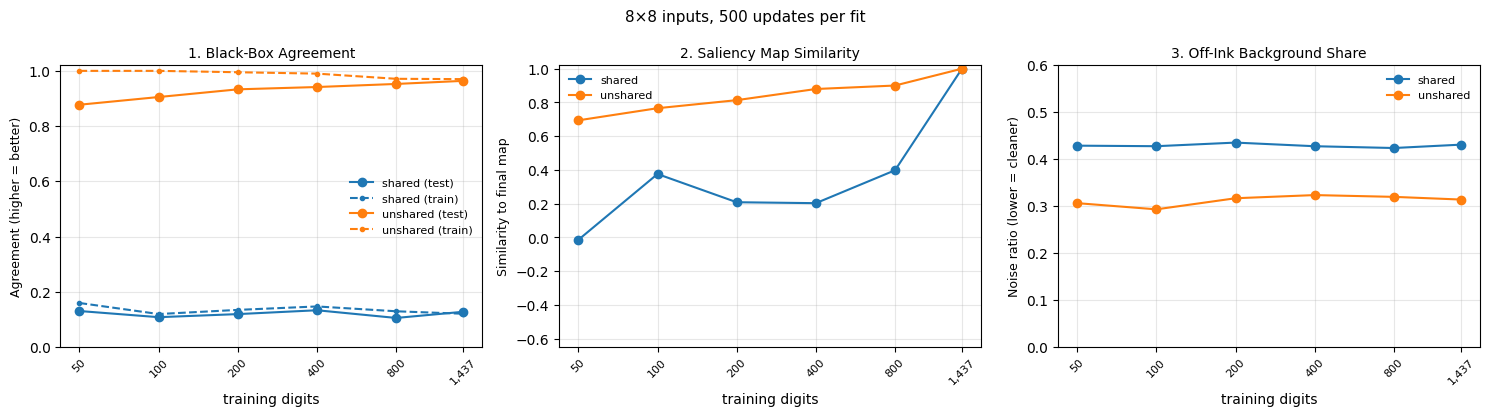

,mode,n_train,epochs,train_agreement,test_agreement,map_vs_last,map_vs_previous,blank_share
0,shared,50,500,0.160,0.131,-0.014,NaN,0.429
1,shared,100,500,0.120,0.109,0.376,0.610,0.428
2,shared,200,500,0.135,0.120,0.209,0.398,0.436
3,shared,400,250,0.148,0.134,0.203,0.604,0.428
4,shared,800,125,0.130,0.106,0.398,0.805,0.424
5,shared,1437,83,0.121,0.128,1.000,0.398,0.431
6,unshared,50,500,1.000,0.877,0.694,NaN,0.307
7,unshared,100,500,1.000,0.905,0.766,0.780,0.293
8,unshared,200,500,0.995,0.933,0.814,0.824,0.317
9,unshared,400,250,0.990,0.942,0.880,0.848,0.324


In [6]:
size_table = sweep()
plot_charts(size_table, f"8×8 inputs, {PARAMS['updates']:,} updates per fit")
size_table.round(3)

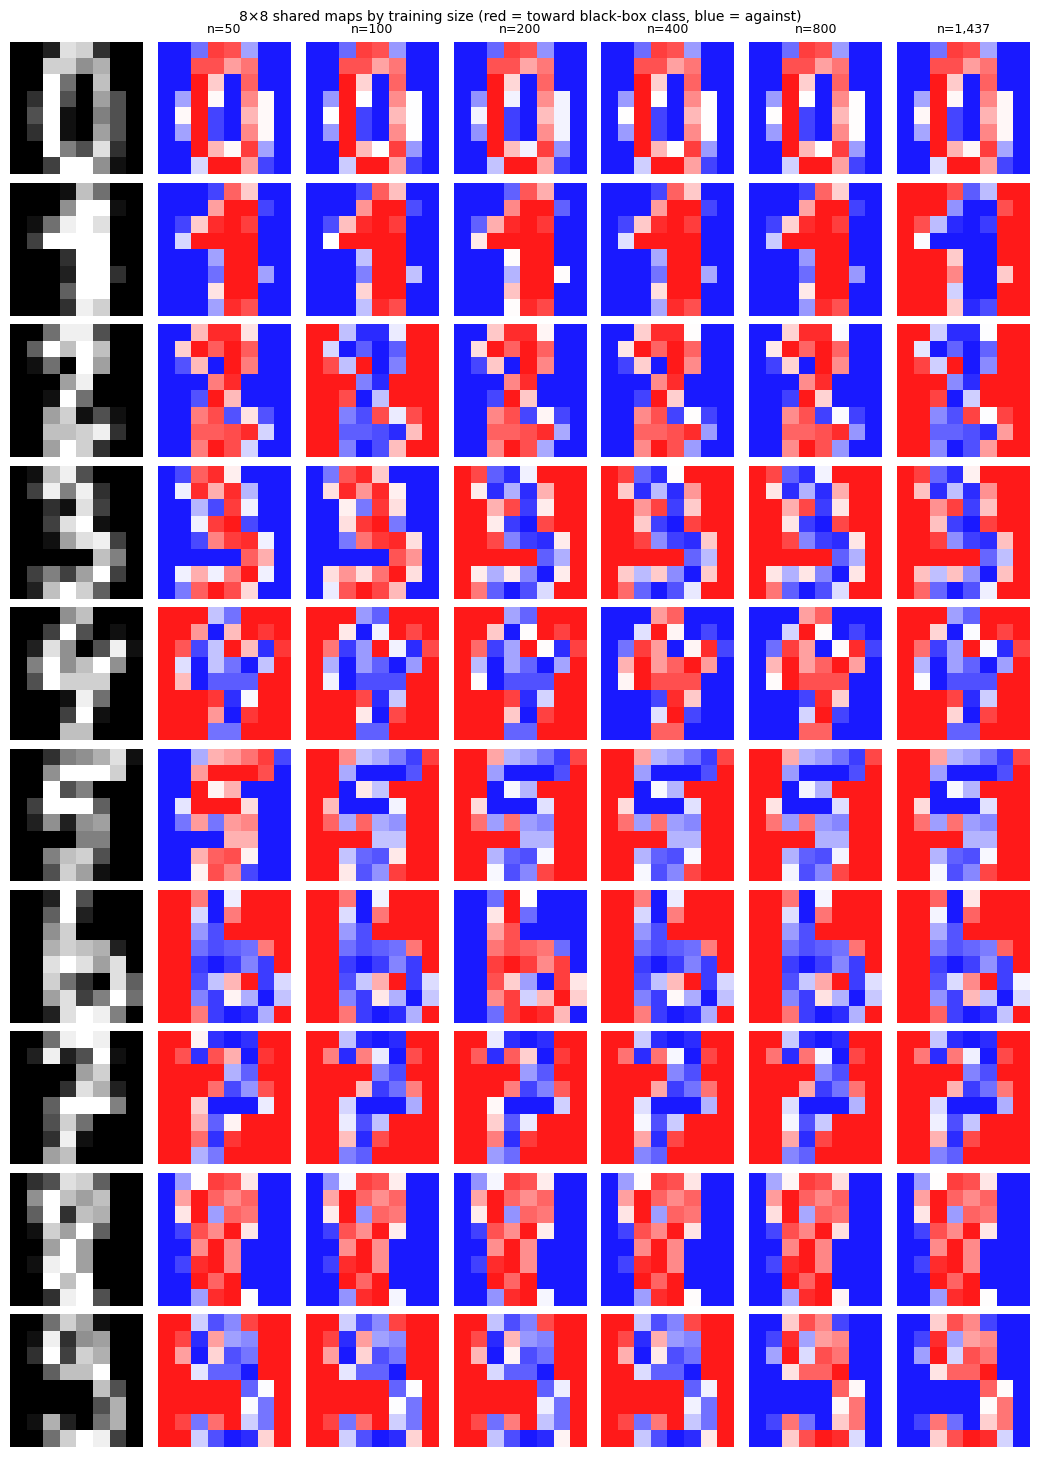

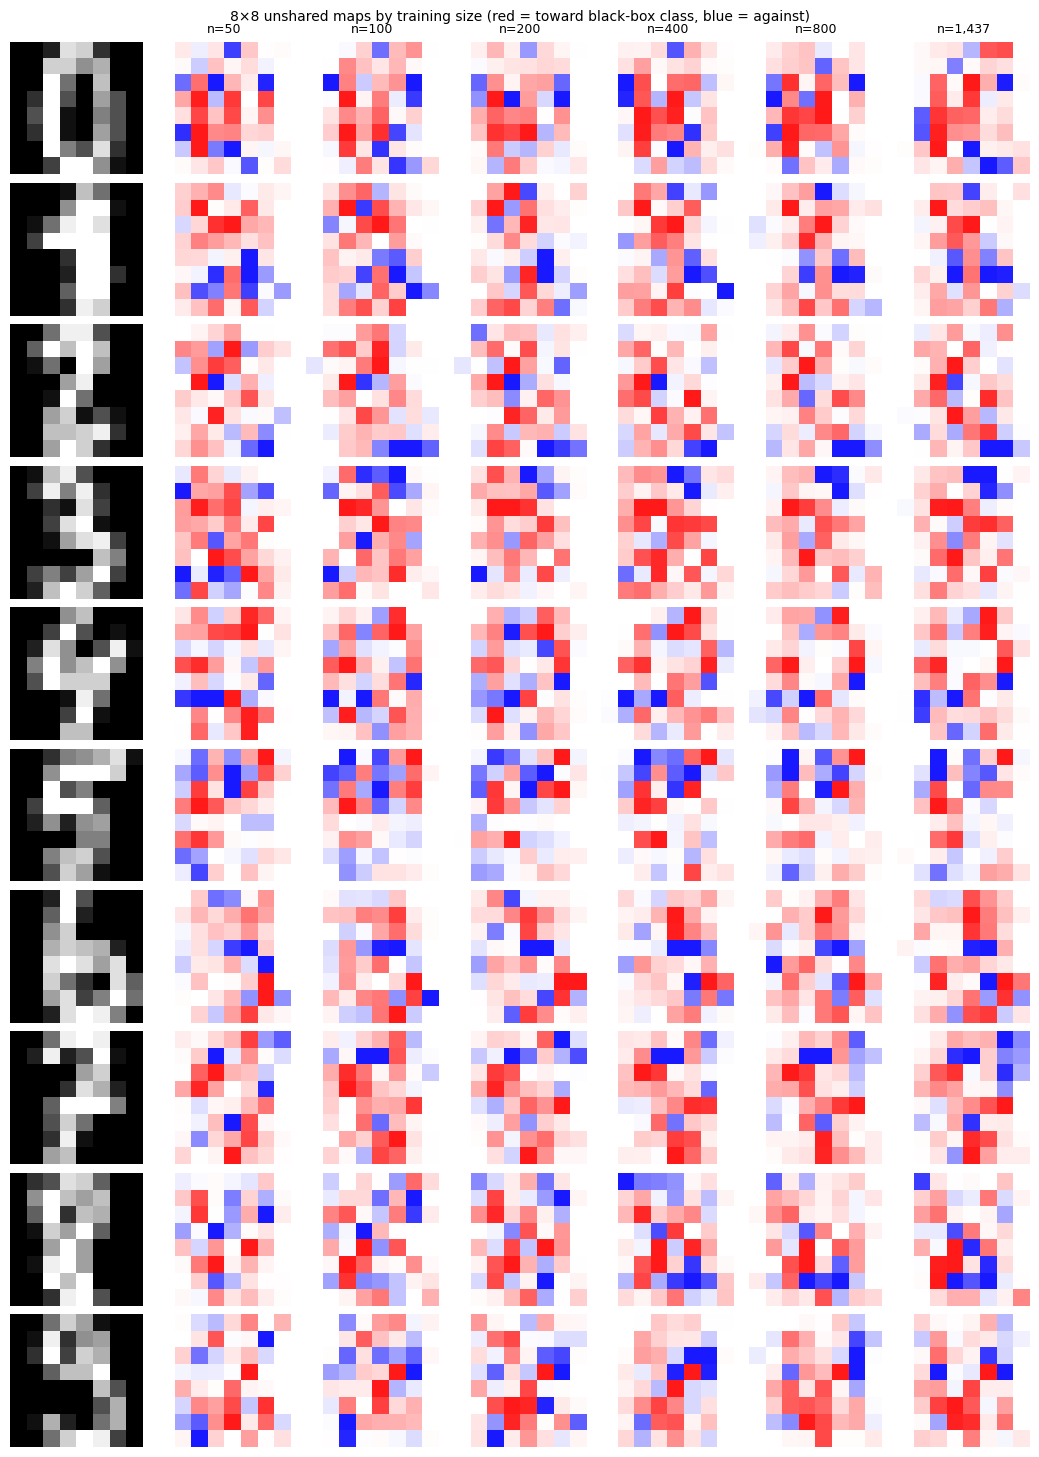

In [7]:
for mode in ["shared", "unshared"]:
    plot_map_grid(mode)

## Shared weights on backbone features

On raw pixels the shared model agrees with the black box only at chance, and its maps swap colours. Explaining the same black box again through 2 different backbones **MobileNetV3-Small** and **ResNet18**.



In [9]:
import torchvision

BACKBONES = ["mobilenet_v3_small", "resnet18"]


def trunk(name):
    if name == "mobilenet_v3_small":
        return torchvision.models.mobilenet_v3_small(weights="DEFAULT").features
    return torch.nn.Sequential(*list(torchvision.models.resnet18(weights="DEFAULT").children())[:-2])  # drop pool + fc


def backbone_features(net, x, batch=256):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            xb = torch.nn.functional.interpolate(torch.from_numpy(x[i:i + batch]).repeat(1, 3, 1, 1), size=224, mode="bilinear")
            out.append(net(((xb - mean) / std).to(DEVICE)).cpu())
    return torch.cat(out).numpy()


feats = {}
for name in BACKBONES:
    net = trunk(name).eval().to(DEVICE)
    feats[name] = (backbone_features(net, pool_x), backbone_features(net, test_x))
    print(name, "features per digit:", feats[name][0].shape[1:])

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /tmp/aru_cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth



  0%|          | 0.00/9.83M [00:00<?, ?B/s]


100%|██████████| 9.83M/9.83M [00:00<00:00, 291MB/s]

mobilenet_v3_small features per digit: (576, 7, 7)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /tmp/aru_cache/torch/hub/checkpoints/resnet18-f37072fd.pth



  0%|          | 0.00/44.7M [00:00<?, ?B/s]


 83%|████████▎ | 37.2M/44.7M [00:00<00:00, 390MB/s]


100%|██████████| 44.7M/44.7M [00:00<00:00, 385MB/s]

resnet18 features per digit: (512, 7, 7)


mobilenet_v3_small tuned (shared): {'batch_size': 256, 'learning_rate': 0.003, 'weight_decay': 0.01, 'updates': 50}


resnet18 tuned (shared): {'batch_size': 256, 'learning_rate': 0.003, 'weight_decay': 0.01, 'updates': 150}


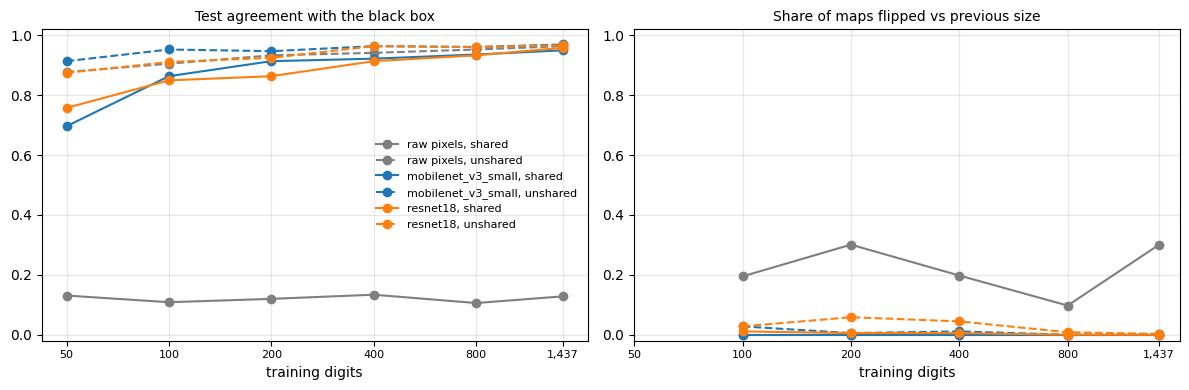

,features,mode,n_train,test_agreement,map_vs_previous,flipped
0,raw pixels,shared,50,0.131,NaN,NaN
1,raw pixels,shared,100,0.109,0.610,0.195
2,raw pixels,shared,200,0.120,0.398,0.301
3,raw pixels,shared,400,0.134,0.604,0.198
4,raw pixels,shared,800,0.106,0.805,0.097
5,raw pixels,shared,1437,0.128,0.398,0.301
6,raw pixels,unshared,50,0.877,NaN,NaN
7,raw pixels,unshared,100,0.905,0.780,0.000
8,raw pixels,unshared,200,0.933,0.824,0.000
9,raw pixels,unshared,400,0.942,0.848,0.000


In [10]:
def corrs(a, b):
    return np.array([np.corrcoef(p.ravel(), q.ravel())[0, 1] for p, q in zip(a, b)])
bfits, BPARAMS = {}, {}

for name in BACKBONES:
    fx, tx = feats[name]
    res = autotune(pool_y, fx, modality="image", search="grid", space=TUNE_SPACE, seed=SEED,
                   device=DEVICE, n_classes=10, share_weights=True)
    p = dict(res.best_params)
    p["updates"] = p.pop("epochs") * updates_per_epoch(len(pool_y) - round(0.25 * len(pool_y)), p["batch_size"])
    print(name, "tuned (shared):", p)
    BPARAMS[name] = p
    for mode in ["shared", "unshared"]:
        for n in SIZES:
            batch = min(p["batch_size"], n)
            epochs = max(1, round(p["updates"] / updates_per_epoch(n, batch)))
            exp = fit_image(pool_y[:n], fx[:n], n_classes=10, share_weights=(mode == "shared"), epochs=epochs,
                            batch_size=batch, learning_rate=p["learning_rate"], weight_decay=p["weight_decay"],
                            seed=SEED, device=DEVICE)
            test_pred = exp.predict(torch.from_numpy(tx)).cpu().numpy()
            imp = np.asarray(exp.get_explanation(tx))
            bfits[(name, mode, n)] = {"row": {"test_agreement": float((test_pred == test_y).mean())},
                                      "map": imp[np.arange(len(test_y)), test_y]}


def get(source, mode, n):
    return fits[(mode, n)] if source == "raw pixels" else bfits[(source, mode, n)]


rows = []
for source in ["raw pixels"] + BACKBONES:
    for mode in ["shared", "unshared"]:
        for j, n in enumerate(SIZES):
            m = get(source, mode, n)["map"]
            c = corrs(m, get(source, mode, SIZES[j - 1])["map"]) if j else None
            rows.append({"features": source, "mode": mode, "n_train": n,
                         "test_agreement": get(source, mode, n)["row"]["test_agreement"],
                         "map_vs_previous": np.nanmean(c) if j else np.nan,
                         "flipped": (c < 0).mean() if j else np.nan})
backbone_table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colours = dict(zip(["raw pixels"] + BACKBONES, ["tab:gray", "tab:blue", "tab:orange"]))
for (source, mode), g in backbone_table.groupby(["features", "mode"], sort=False):
    style = dict(marker="o", color=colours[source], ls="-" if mode == "shared" else "--", label=f"{source}, {mode}")
    axes[0].plot(g.n_train, g.test_agreement, **style)
    axes[1].plot(g.n_train, g.flipped, **style)
for ax, title in zip(axes, ["Test agreement with the black box", "Share of maps flipped vs previous size"]):
    ax.set_xscale("log")
    ax.set_xticks(SIZES, [f"{v:,}" for v in SIZES], fontsize=8)
    ax.minorticks_off()
    ax.set_xlabel("training digits")
    ax.set_title(title, fontsize=10)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
backbone_table.round(3)

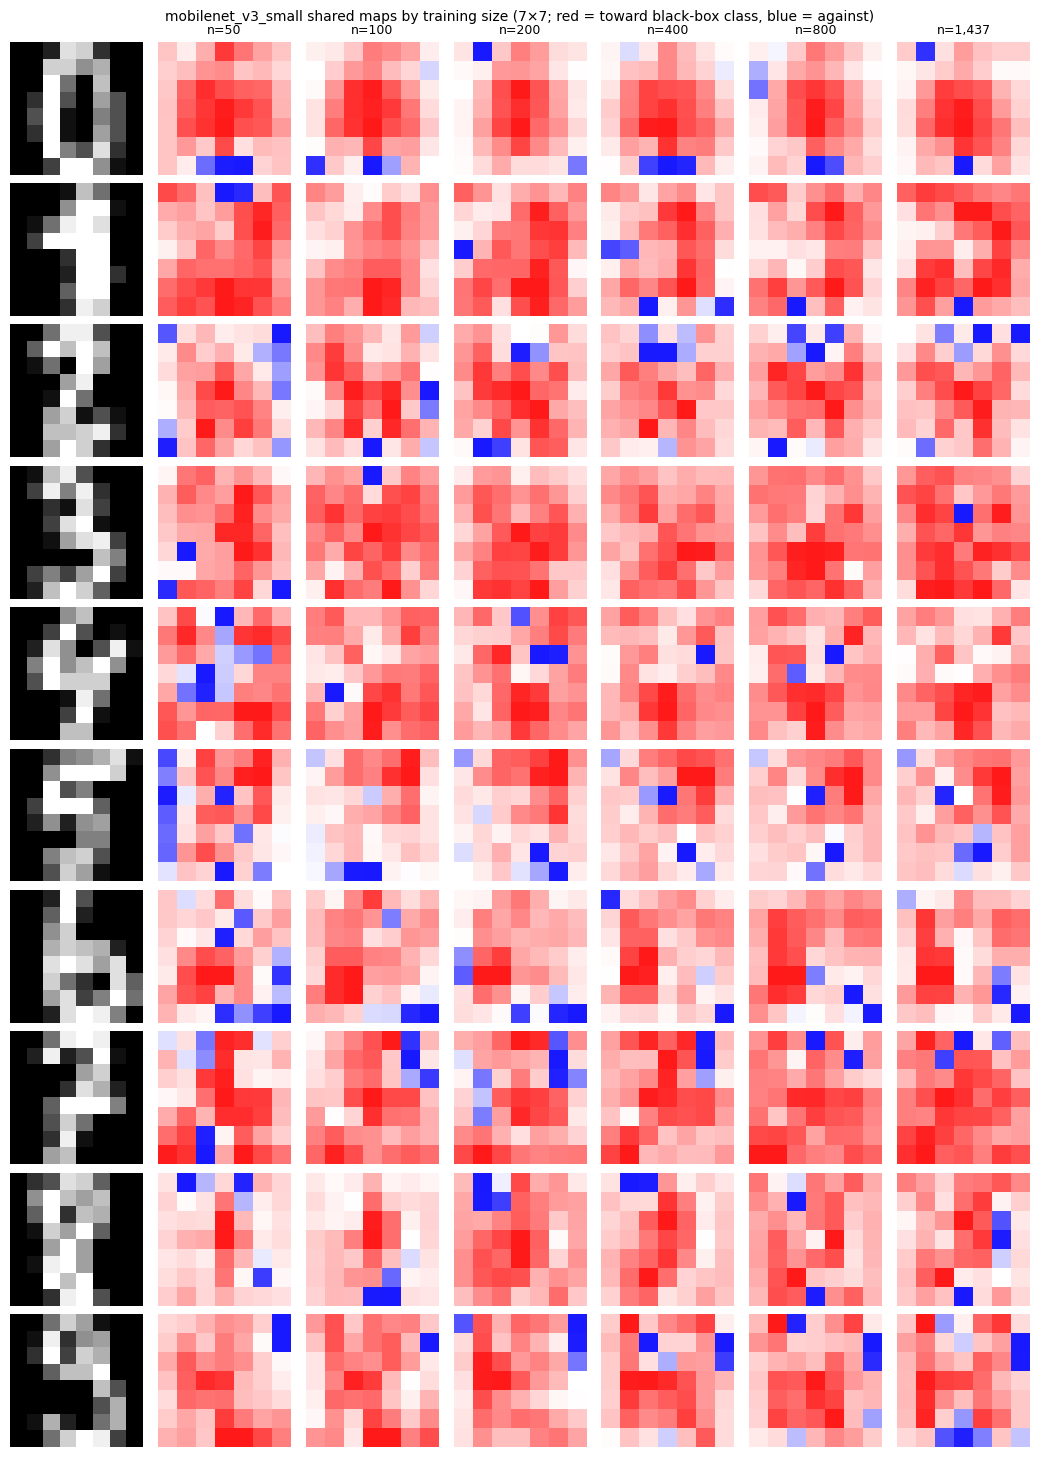

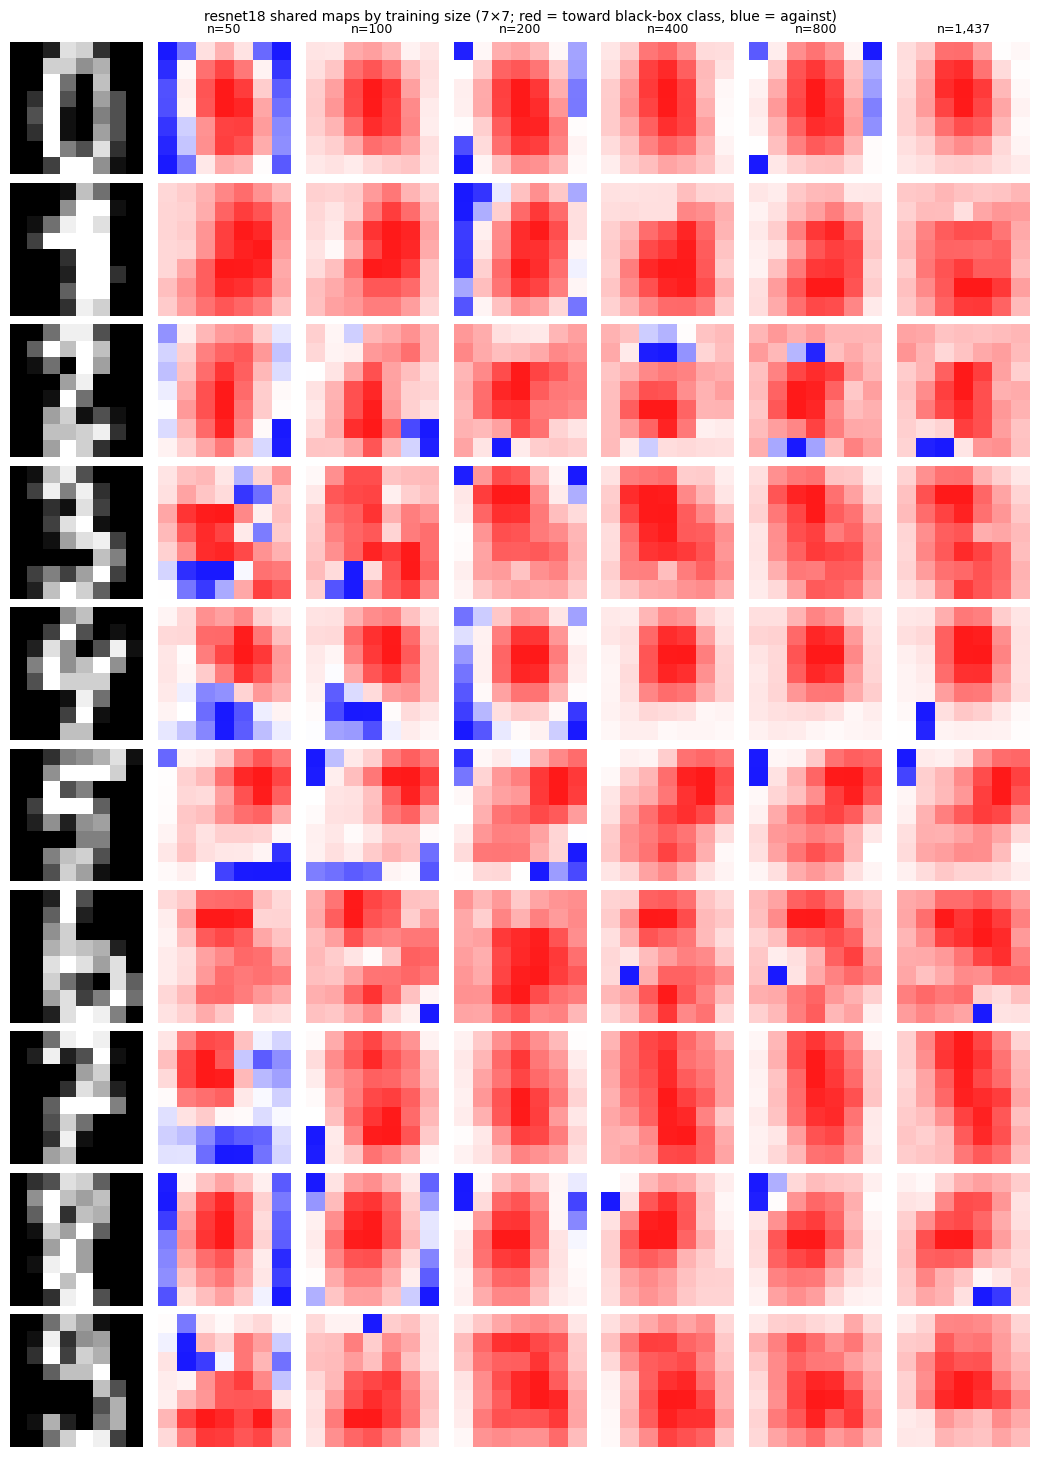

In [11]:
for name in BACKBONES:
    fig, axes = plt.subplots(10, len(SIZES) + 1, figsize=(1.5 * (len(SIZES) + 1), 15))
    for row, i in enumerate(ROWS):
        show_digit(test_x[i, 0], axes[row, 0])
        for j, n in enumerate(SIZES):
            show_map(bfits[(name, "shared", n)]["map"][i], axes[row, j + 1])
            if row == 0:
                axes[row, j + 1].set_title(f"n={n:,}", fontsize=9)
    fig.suptitle(f"{name} shared maps by training size (7×7; red = toward black-box class, blue = against)", fontsize=10)
    fig.tight_layout()
    plt.show()

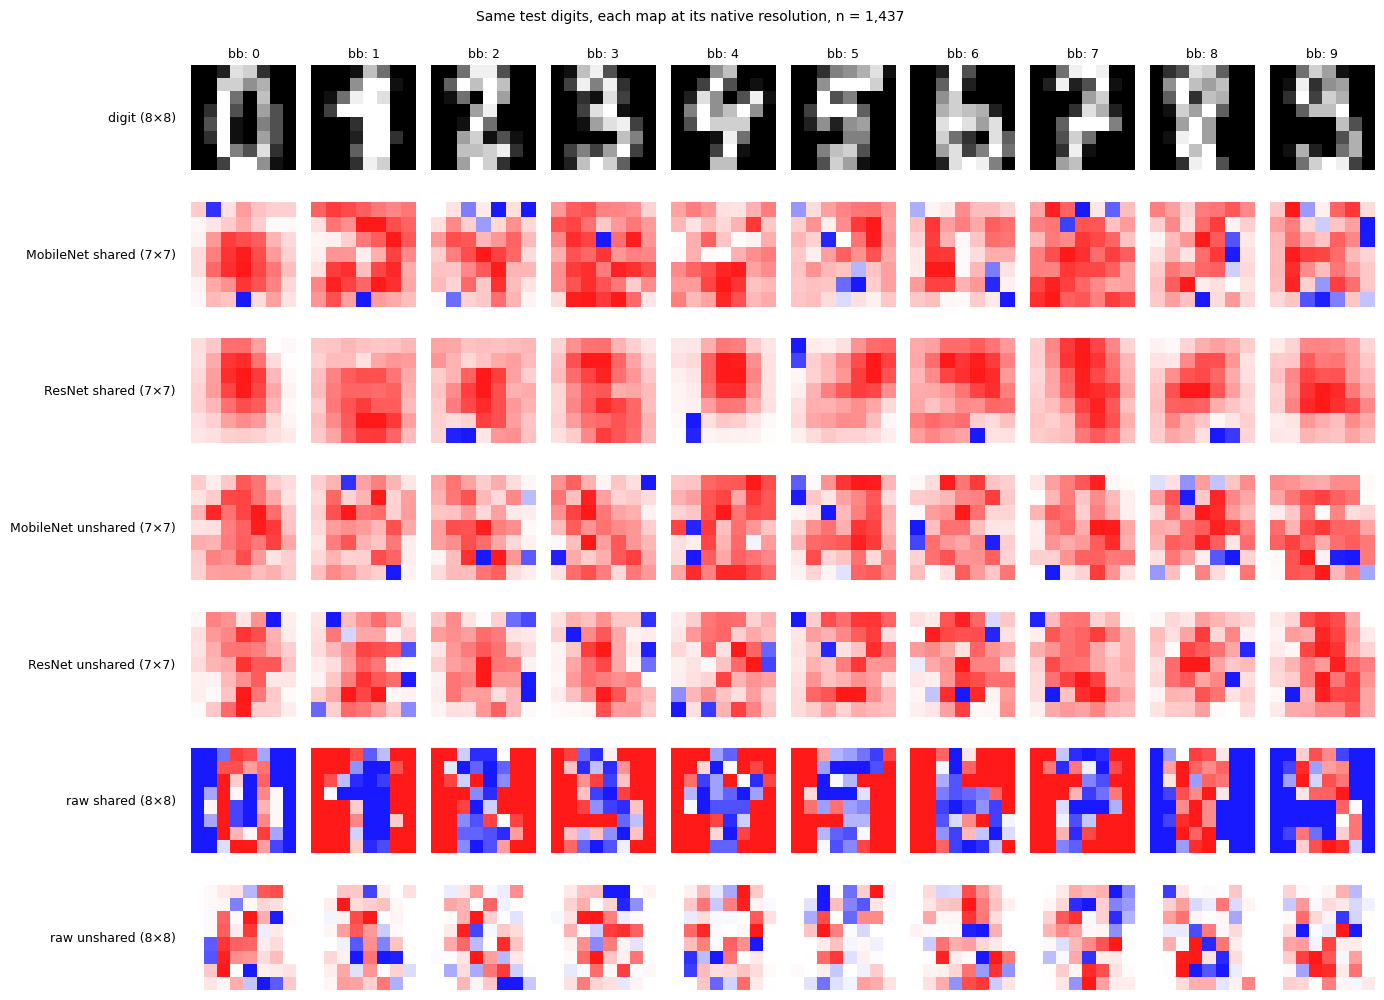

,pair,mean_corr_on_7x7,opposite_sign
0,MobileNet shared vs ResNet shared,0.361,0.106
1,MobileNet unshared vs ResNet unshared,0.361,0.011
2,MobileNet shared vs MobileNet unshared,0.382,0.033
3,ResNet shared vs ResNet unshared,0.523,0.025
4,MobileNet shared vs raw shared,-0.081,0.643
5,ResNet shared vs raw shared,-0.177,0.688
6,MobileNet shared vs raw unshared,0.235,0.181
7,ResNet shared vs raw unshared,0.242,0.181


In [ ]:
n = SIZES[-1]
mob, res = BACKBONES
panels = {
    "MobileNet shared": bfits[(mob, "shared", n)]["map"],
    "ResNet shared": bfits[(res, "shared", n)]["map"],
    "MobileNet unshared": bfits[(mob, "unshared", n)]["map"],
    "ResNet unshared": bfits[(res, "unshared", n)]["map"],
    "raw shared": fits[("shared", n)]["map"],
    "raw unshared": fits[("unshared", n)]["map"],
}

def to7(m):
    return m if m.shape[-1] == 7 else torch.nn.functional.adaptive_avg_pool2d(torch.from_numpy(m[:, None]), 7)[:, 0].numpy()
pairs = [("MobileNet shared", "ResNet shared"), ("MobileNet unshared", "ResNet unshared"),
         ("MobileNet shared", "MobileNet unshared"), ("ResNet shared", "ResNet unshared"),
         ("MobileNet shared", "raw shared"), ("ResNet shared", "raw shared"),
         ("MobileNet shared", "raw unshared"), ("ResNet shared", "raw unshared")]
similarity = pd.DataFrame([{"pair": f"{a} vs {b}", "mean_corr_on_7x7": np.nanmean(c := corrs(to7(panels[a]), to7(panels[b]))),
                            "opposite_sign": (c < 0).mean()} for a, b in pairs])

fig, axes = plt.subplots(len(panels) + 1, 10, figsize=(14, 10.5))
for k, i in enumerate(ROWS):
    show_digit(test_x[i, 0], axes[0, k])
    axes[0, k].set_title(f"bb: {test_y[i]}", fontsize=9)
    for r, maps in enumerate(panels.values()):
        show_map(maps[i], axes[r + 1, k])
for r, label in enumerate(["digit (8×8)"] + [f"{p} ({'7×7' if m.shape[-1] == 7 else '8×8'})" for p, m in panels.items()]):
    axes[r, 0].text(-0.15, 0.5, label, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
fig.suptitle(f"Same test digits, each map at its native resolution, n = {n:,}", fontsize=10)
fig.tight_layout()
plt.show()
similarity.round(3)
